# Catching Credit Card Fraud with a Neural Network

**Goal:** teach a neural network to look at a card transaction and decide: *normal* or *fraud*?

**Why this project is interesting**

- The data is real: **284,807 card transactions** made by European cardholders over two days (about 100 MB).
- Only **492** of them are fraud — roughly 1 in 600. Finding them is like finding a needle in a haystack.
- It teaches a famous lesson: **a model can be 99.8% accurate and still be completely useless.**

**Type of problem:** supervised learning, binary classification, all inputs are numbers.

**Steps**
1. Download the data
2. Explore it
3. Prepare it (split + scale)
4. The "accuracy trap"
5. Build the neural network
6. Train it
7. Evaluate it
8. Play with the decision threshold
9. Exercises

In [1]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, precision_score, recall_score

keras.utils.set_random_seed(42)   # same results every run
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 1. Download the data

The file is about 100 MB, so the first run takes a minute. After that it is read from disk.

In [2]:
URL  = "https://raw.githubusercontent.com/nsethi31/Kaggle-Data-Credit-Card-Fraud-Detection/master/creditcard.csv"
FILE = "creditcard.csv"

if not os.path.exists(FILE):
    print("Downloading... (about 100 MB)")
    urllib.request.urlretrieve(URL, FILE)

print(f"File size: {os.path.getsize(FILE) / 1e6:.0f} MB")
df = pd.read_csv(FILE)
print("Rows, columns:", df.shape)
df.head()

File size: 103 MB


Rows, columns: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Explore the data

Each row is one transaction.

| Column | Meaning |
|---|---|
| `Time` | seconds since the first transaction in the file |
| `V1` … `V28` | 28 numeric features. The bank hid the real meaning (for customer privacy) using a technique called PCA |
| `Amount` | transaction amount in euros |
| `Class` | **the answer we want to predict:** 0 = normal, 1 = fraud |

Normal transactions: 284,315
Fraud transactions : 492
Fraud share        : 0.173%


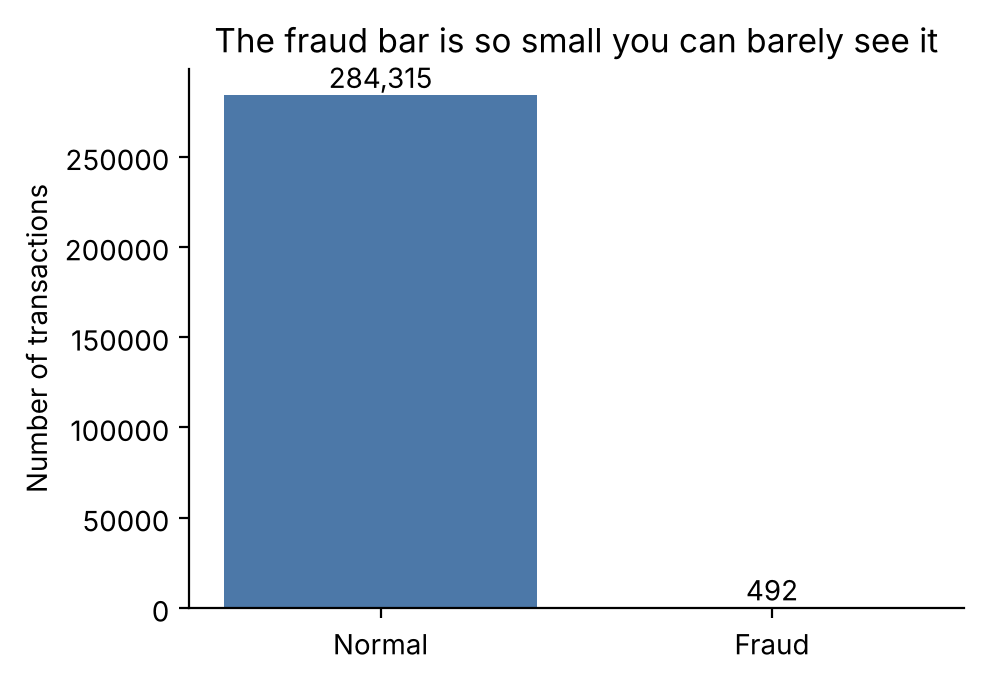

In [3]:
counts = df["Class"].value_counts()
print("Normal transactions:", f"{counts[0]:,}")
print("Fraud transactions :", f"{counts[1]:,}")
print(f"Fraud share        : {counts[1] / len(df):.3%}")

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(["Normal", "Fraud"], counts.values, color=["#4C78A8", "#E45756"])
ax.bar_label(bars, labels=[f"{v:,}" for v in counts.values])
ax.set_title("The fraud bar is so small you can barely see it")
ax.set_ylabel("Number of transactions")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Do fraud transactions *look* different? Let's compare two of the hidden features. If the blue and red shapes are separated, the network has something to learn from.

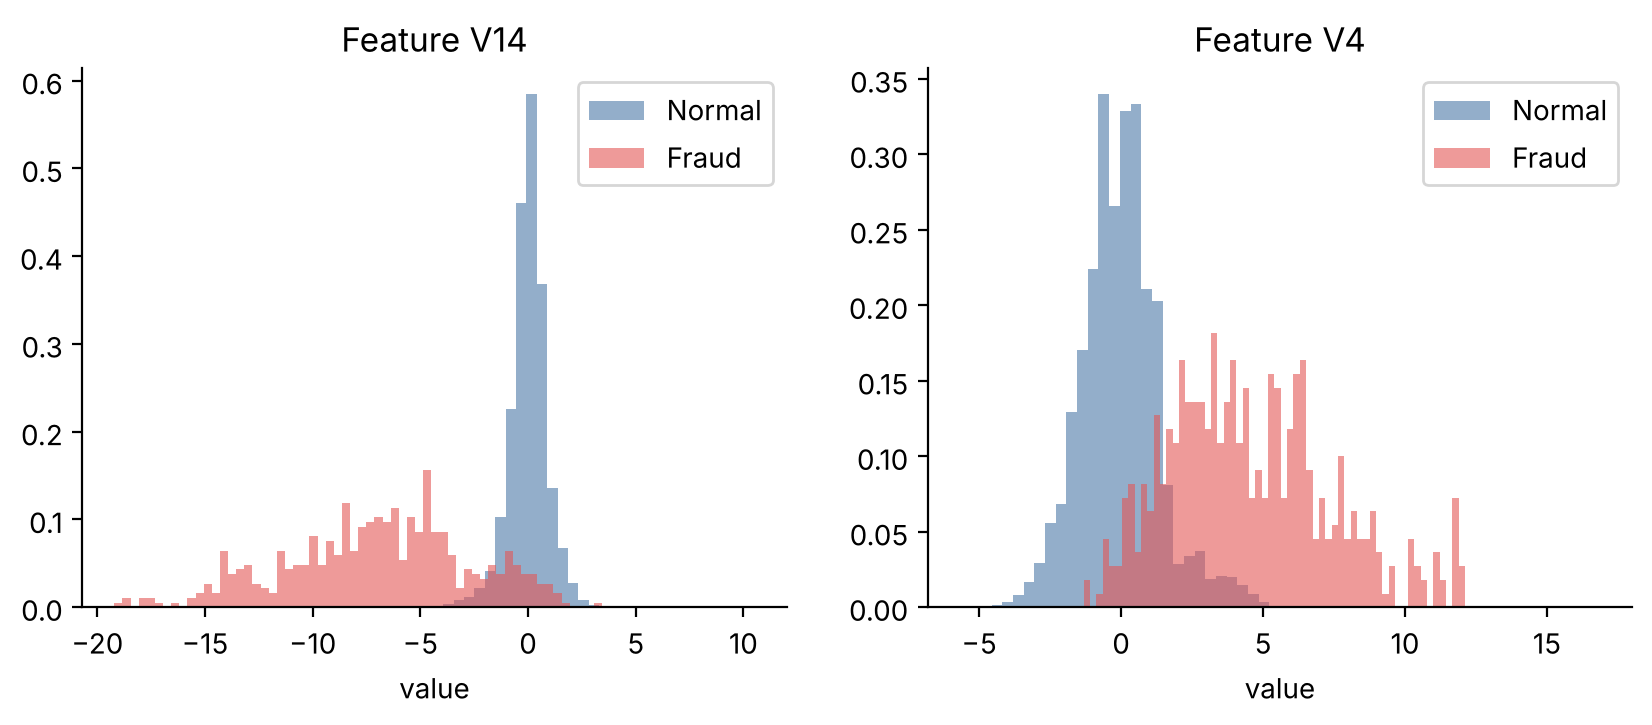

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.21,256.68,0.0,1.00,9.25,105.89,2125.87


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, ["V14", "V4"]):
    ax.hist(df.loc[df.Class == 0, col], bins=60, density=True, alpha=0.6, color="#4C78A8", label="Normal")
    ax.hist(df.loc[df.Class == 1, col], bins=60, density=True, alpha=0.6, color="#E45756", label="Fraud")
    ax.set_title(f"Feature {col}")
    ax.set_xlabel("value")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend()
plt.show()

df.groupby("Class")["Amount"].describe().round(2)

## 3. Prepare the data

Three small steps:

1. **Choose inputs (X) and answer (y).** We drop `Time` (it is just a counter) and take the log of `Amount`, because amounts range from 0 to 25,000 and a few huge values would dominate.
2. **Split** into three parts: *train* (the network learns from this), *validation* (we watch this during training), *test* (the final exam — never seen during training).
3. **Scale** every column to mean 0 and standard deviation 1. Neural networks learn much faster when all inputs are on a similar scale.

In [5]:
X = df.drop(columns=["Time", "Class"]).copy()
X["Amount"] = np.log1p(X["Amount"])
y = df["Class"].values

# 64% train, 16% validation, 20% test. stratify keeps the fraud share equal in each part.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val,  y_train, y_val  = train_test_split(X_train, y_train, test_size=0.20, stratify=y_train, random_state=42)

scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train)   # learn the scale from train only...
X_val   = scaler.transform(X_val)         # ...then apply the same scale to the rest
X_test  = scaler.transform(X_test)

for name, part in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:<11} {len(part):>7,} rows   {part.sum():>3} frauds")

Train       182,276 rows   315 frauds
Validation   45,569 rows    79 frauds
Test         56,962 rows    98 frauds


## 4. The accuracy trap

Before building anything, meet the laziest model in the world: it says **"normal"** for every transaction.

In [6]:
lazy_predictions = np.zeros_like(y_test)

print(f"Accuracy of the lazy model: {(lazy_predictions == y_test).mean():.2%}")
print(f"Frauds caught             : {lazy_predictions[y_test == 1].sum()} out of {y_test.sum()}")

Accuracy of the lazy model: 99.83%
Frauds caught             : 0 out of 98


**99.8% accurate, zero frauds caught.** Accuracy is the wrong score for this problem. We will use two better ones:

- **Recall** — of all real frauds, what share did we catch?
- **Precision** — of all our fraud alarms, what share were real?

## 5. Build the neural network

A small network is enough:

```
29 inputs  →  32 neurons (ReLU)  →  16 neurons (ReLU)  →  1 neuron (sigmoid)
```

- **ReLU** lets the network learn curved, non-linear patterns.
- **Dropout** randomly switches off 30% of neurons during training, so the network cannot simply memorise.
- **Sigmoid** squeezes the final output into a number between 0 and 1: the *probability of fraud*.

In [7]:
model = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[keras.metrics.Precision(name="precision"),
             keras.metrics.Recall(name="recall"),
             keras.metrics.AUC(name="auc", curve="PR")],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,505 (5.88 KB)

 Trainable params: 1,505 (5.88 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train

One trick: **class weights**. Because fraud is so rare, we tell the network that missing one fraud is as bad as getting hundreds of normal transactions wrong. Otherwise it would learn to behave like the lazy model.

**Early stopping** ends training when the validation loss stops improving, and keeps the best version.

In [8]:
n_normal, n_fraud = np.bincount(y_train)
class_weight = {0: len(y_train) / (2 * n_normal),
                1: len(y_train) / (2 * n_fraud)}
print(f"Weight of a normal transaction: {class_weight[0]:.2f}")
print(f"Weight of a fraud transaction : {class_weight[1]:.0f}")

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=2048,          # big batches so each one contains a few frauds
    class_weight=class_weight,
    callbacks=[early_stop],
    verbose=2,
)

Weight of a normal transaction: 0.50
Weight of a fraud transaction : 289
Epoch 1/40


90/90 - 1s - 14ms/step - auc: 0.2408 - loss: 0.4453 - precision: 0.0038 - recall: 0.9175 - val_auc: 0.6758 - val_loss: 0.4349 - val_precision: 0.0214 - val_recall: 0.8734


Epoch 2/40


90/90 - 0s - 5ms/step - auc: 0.6793 - loss: 0.2542 - precision: 0.0283 - recall: 0.8921 - val_auc: 0.6804 - val_loss: 0.2383 - val_precision: 0.0512 - val_recall: 0.8861


Epoch 3/40


90/90 - 0s - 4ms/step - auc: 0.6347 - loss: 0.1907 - precision: 0.0499 - recall: 0.9016 - val_auc: 0.6834 - val_loss: 0.1572 - val_precision: 0.0627 - val_recall: 0.8734


... (70 outputs left out)

Epoch 39/40


90/90 - 0s - 4ms/step - auc: 0.7289 - loss: 0.0307 - precision: 0.1241 - recall: 0.9937 - val_auc: 0.6824 - val_loss: 0.0315 - val_precision: 0.1234 - val_recall: 0.8608


Epoch 40/40


90/90 - 1s - 7ms/step - auc: 0.7439 - loss: 0.0284 - precision: 0.1352 - recall: 0.9937 - val_auc: 0.6618 - val_loss: 0.0314 - val_precision: 0.1234 - val_recall: 0.8608


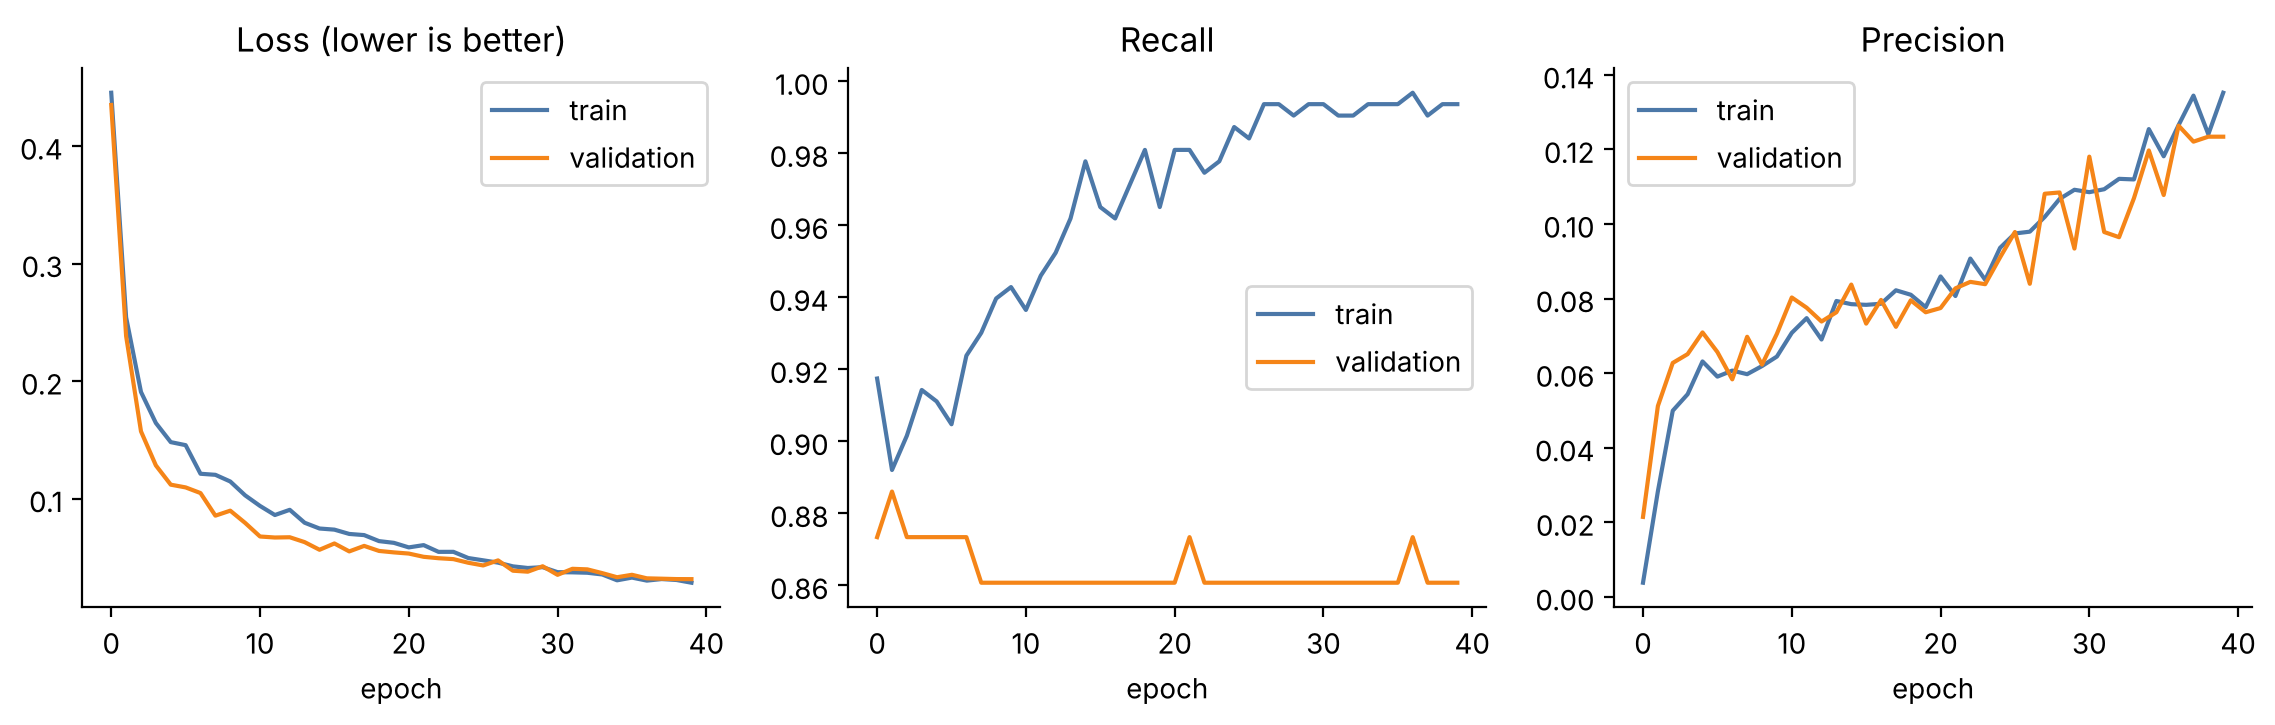

In [9]:
h = history.history
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, key, title in zip(axes, ["loss", "recall", "precision"], ["Loss (lower is better)", "Recall", "Precision"]):
    ax.plot(h[key], color="#4C78A8", label="train")
    ax.plot(h["val_" + key], color="#F58518", label="validation")
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend()
plt.show()

## 7. Evaluate on the test set

The test set is the final exam: 56,962 transactions the network has never seen. If the fraud probability is above 0.5, we raise an alarm.

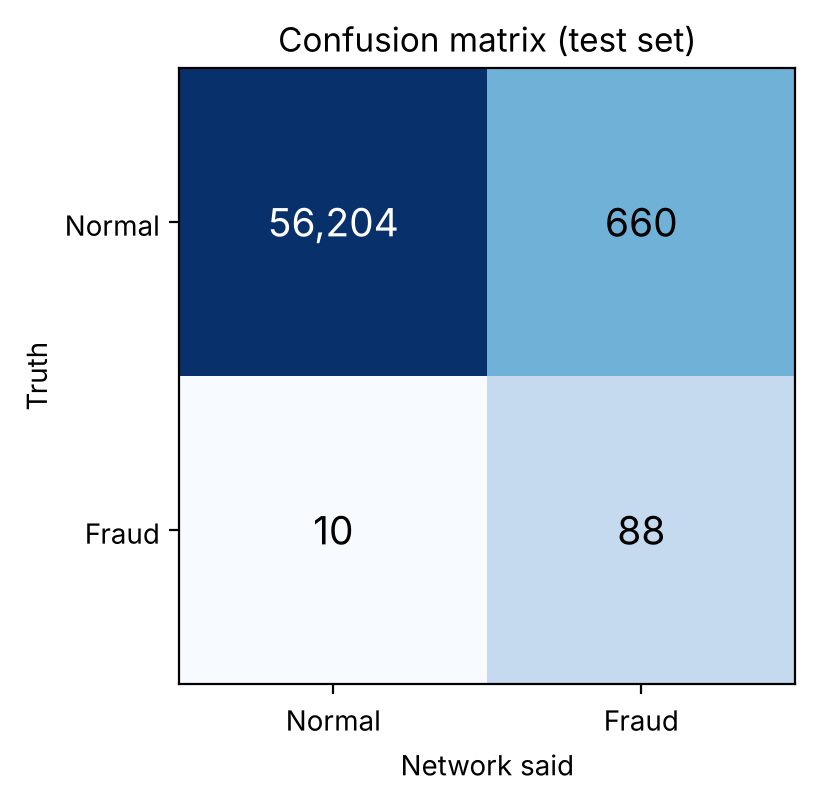

Frauds caught       : 88 out of 98   (recall    = 89.8%)
Frauds missed       : 10
False alarms        : 660 out of 56,864 normal transactions
Alarms that are real: 88 out of 748   (precision = 11.8%)


In [10]:
prob_test = model.predict(X_test, batch_size=4096, verbose=0).ravel()
pred_test = (prob_test >= 0.5).astype(int)

cm = confusion_matrix(y_test, pred_test)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues", norm="log")
ax.set_xticks([0, 1], ["Normal", "Fraud"]); ax.set_yticks([0, 1], ["Normal", "Fraud"])
ax.set_xlabel("Network said"); ax.set_ylabel("Truth")
ax.set_title("Confusion matrix (test set)")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > 1000 else "black")
plt.show()

print(f"Frauds caught       : {tp} out of {tp + fn}   (recall    = {tp / (tp + fn):.1%})")
print(f"Frauds missed       : {fn}")
print(f"False alarms        : {fp:,} out of {tn + fp:,} normal transactions")
print(f"Alarms that are real: {tp} out of {tp + fp}   (precision = {tp / (tp + fp):.1%})")

Compare with the lazy model: it caught **0** frauds. The network catches most of them — but it also raises false alarms. That is the price of the class weights: we told it that missing a fraud is very costly, so it prefers to be suspicious.

Can we control that trade-off? Yes.

## 8. Play with the threshold

The network outputs a probability. *We* decide how high it must be before we raise an alarm.

- **Low threshold** → more alarms → catch more fraud, annoy more honest customers.
- **High threshold** → fewer alarms → fewer angry customers, more fraud slips through.

There is no "correct" answer. It is a business decision.

In [11]:
rows = []
for t in [0.10, 0.30, 0.50, 0.70, 0.90, 0.99]:
    pred = (prob_test >= t).astype(int)
    rows.append({"threshold": t,
                 "frauds caught": int(pred[y_test == 1].sum()),
                 "frauds missed": int((1 - pred[y_test == 1]).sum()),
                 "false alarms": int(pred[y_test == 0].sum()),
                 "recall": round(recall_score(y_test, pred), 3),
                 "precision": round(precision_score(y_test, pred, zero_division=0), 3)})
table = pd.DataFrame(rows).set_index("threshold")
table

,frauds caught,frauds missed,false alarms,recall,precision
threshold,,,,,
0.10,91,7,1776,0.929,0.049
0.30,88,10,978,0.898,0.083
0.50,88,10,660,0.898,0.118
0.70,88,10,386,0.898,0.186
0.90,86,12,152,0.878,0.361
0.99,83,15,36,0.847,0.697


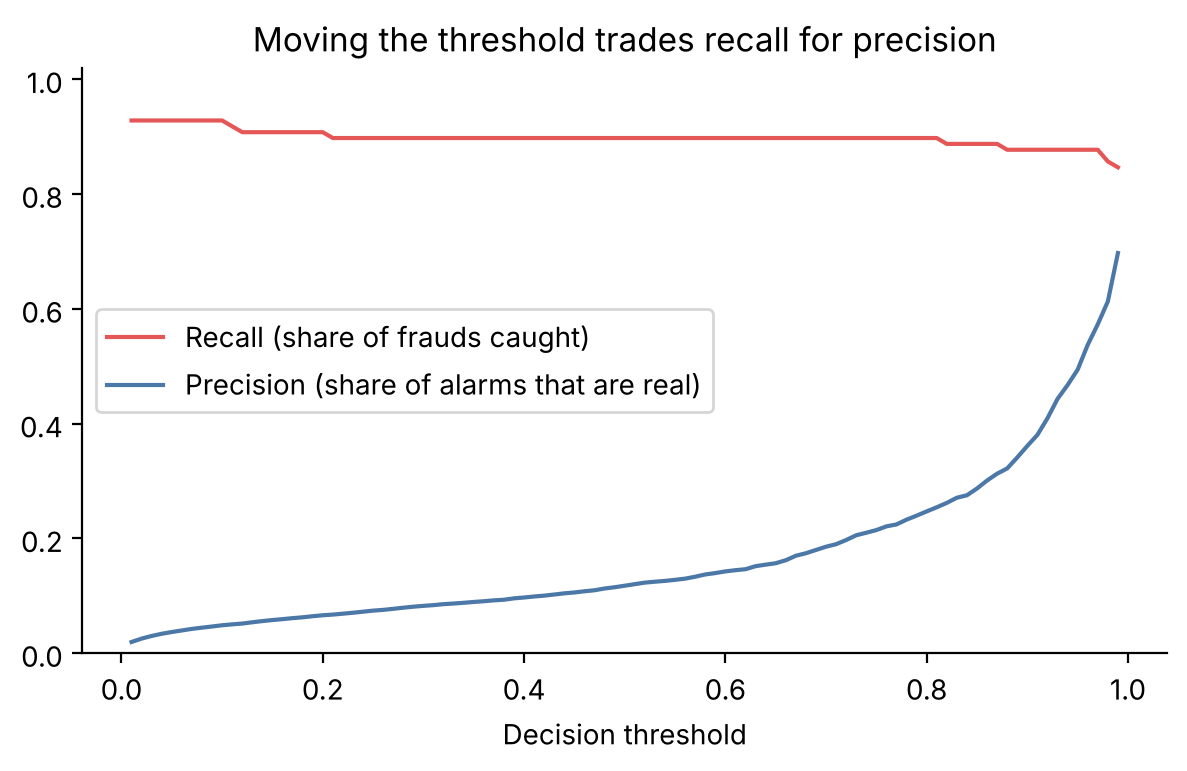

In [12]:
thresholds = np.linspace(0.01, 0.99, 99)
recalls    = [recall_score(y_test, prob_test >= t) for t in thresholds]
precisions = [precision_score(y_test, prob_test >= t, zero_division=0) for t in thresholds]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(thresholds, recalls, color="#E45756", label="Recall (share of frauds caught)")
ax.plot(thresholds, precisions, color="#4C78A8", label="Precision (share of alarms that are real)")
ax.set_xlabel("Decision threshold"); ax.set_ylim(0, 1.02)
ax.set_title("Moving the threshold trades recall for precision")
ax.spines[["top", "right"]].set_visible(False)
ax.legend()
plt.show()

## 9. What we learned

1. A neural network is just layers of simple units. Three `Dense` layers were enough.
2. Scaling the inputs matters.
3. **Accuracy can lie** when one class is rare. Use precision and recall.
4. Class weights make the network pay attention to the rare class.
5. The threshold turns a probability into a decision, and choosing it is a business question.

## Exercises

1. Remove `class_weight=class_weight` from `model.fit` and retrain. What happens to recall and to false alarms?
2. Change the network: try `Dense(8)` only, or add a third hidden layer with 64 neurons. Does it help?
3. Skip the scaling step (use the raw values). How does training change?
4. A missed fraud costs the bank €120 on average and a false alarm costs €2 (a phone call). Using the threshold table, which threshold is cheapest?
5. Set `Dropout(0.0)` and train for 40 epochs without early stopping. Compare the train and validation curves. What do you see?